<a href="https://colab.research.google.com/github/Leenmbr/drone-detection-yolov8/blob/main/Drone_Detection_YOLOv8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Drone** **Detection** **using** **YOLOv8**

In this project we train a YOLOv8 model to detect DJI Tello drones in images and draw a box around each drone. Drone detection is useful for security, for example to spot drones flying near airports or private areas.

---



## Step 1 — Loading the dataset
We download the DJI Tello Drone Object Detection dataset from Kaggle using kagglehub. The dataset is already labeled in YOLO format and split into train, valid and test folders. We then read its data.yaml file to check the class name (tello drone quadcopter) and the folder paths.




In [9]:
import kagglehub

# Download the dataset / نحمّل البيانات
path = kagglehub.dataset_download("luispreciado99/dji-tello-drone-object-detection-dataset")

print("Path to dataset files:", path)


Using Colab cache for faster access to the 'dji-tello-drone-object-detection-dataset' dataset.
Path to dataset files: /kaggle/input/dji-tello-drone-object-detection-dataset


In [10]:
# Load dataset configuration / نطّلع على إعدادات البيانات
dataset_path = path + "/data.yaml" #file generated by Roboflow for your object-detection dataset. It tells YOLO where the images are and what the classes are

# Check dataset information -- this lists the class names and where train/valid/test live
print(open(dataset_path).read())


train: ../train/images
val: ../valid/images
test: ../test/images

nc: 1
names: ['tello drone quadcopter']

roboflow:
  workspace: yolo-groundeddino-dataset
  project: yolo-tello-drone-9eml6
  version: 6
  license: CC BY 4.0
  url: https://universe.roboflow.com/yolo-groundeddino-dataset/yolo-tello-drone-9eml6/dataset/6


## Step 2 — Loading a pretrained YOLOv8 model
We install the Ultralytics library and load YOLOv8 small (yolov8s.pt). This model was trained before on the COCO dataset, so it already knows general shapes and objects, but it has never learned what a drone is.

In [11]:
# Install Ultralytics library which has YOLO | نُثبّت مكتبة Ultralytics
!pip install -q ultralytics


In [12]:
from ultralytics import YOLO
import matplotlib.pyplot as plt

# Load YOLOv8 model (small version) / نحمّل نموذج YOLOv8 (النسخة الصغيرة)
model = YOLO("yolov8s.pt")


## Step 3 — Testing the model before training
We run the pretrained model on one test image to see how it performs before training on our data.






Number of test images: 129

image 1/1 /kaggle/input/dji-tello-drone-object-detection-dataset/test/images/IMG_4090_jpg.rf.d0d542ee69e42cfd8c495245dab6a27e.jpg: 640x640 1 bench, 23.7ms
Speed: 1.2ms preprocess, 23.7ms inference, 4.4ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict-3


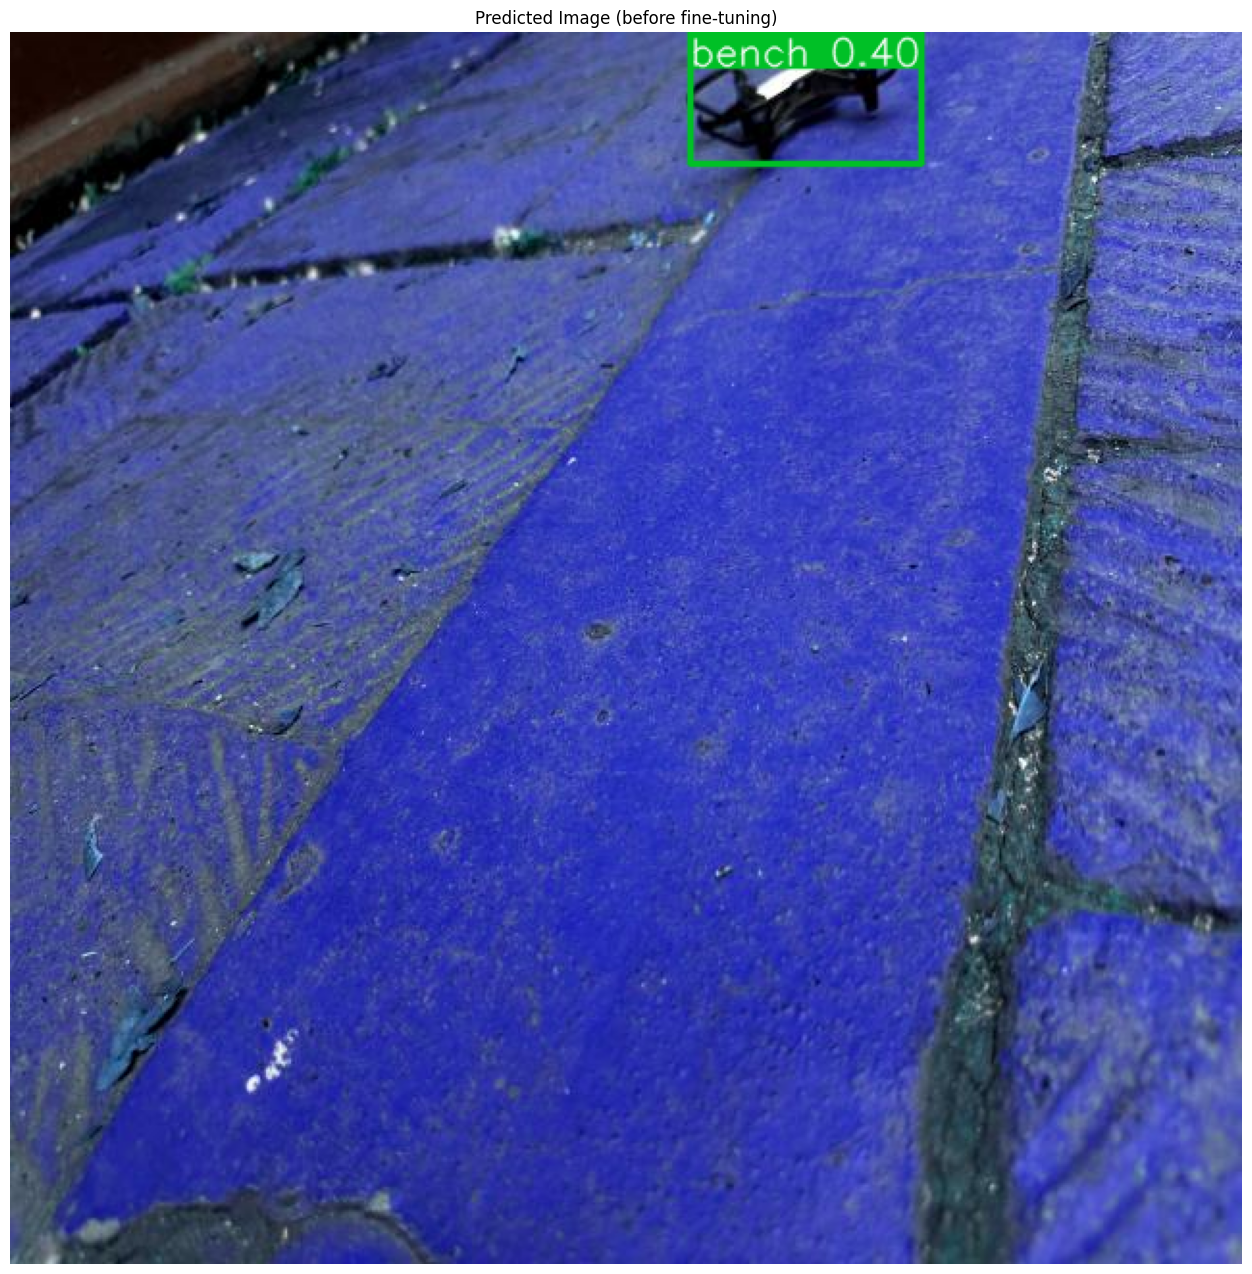

In [13]:
# Load an image and run inference / نُحمّل صورة ونُجري تنبؤًا
from pathlib import Path

test_images = [
    p for p in Path(path).rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    and p.parent.name == "images"
    and p.parent.parent.name == "test"
]

print("Number of test images:", len(test_images))

if not test_images:
    raise FileNotFoundError("No test images found")

results = model(str(test_images[0]), save=True)

# Convert result to a NumPy array and display / نحوّل النتيجة إلى صورة ونعرضها
predicted_image = results[0].plot()

plt.figure(figsize=(16, 16))
plt.imshow(predicted_image)
plt.axis("off")
plt.title("Predicted Image (before fine-tuning)")
plt.show()


## Step 4 — Training YOLOv8 on our dataset
We fine-tune the model on 602 training images for 6 epochs, with image size 640×640. The data.yaml file tells YOLO where the images and labels are.



In [14]:
# Train on the drone dataset /
model.train(data=dataset_path, epochs=6, imgsz=640)


Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/dji-tello-drone-object-detection-dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=6, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d4677a5e8a0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

* cls_loss (Classification Loss): Measures how accurately the model classifies detected objects into the correct class.

*	box_loss (Bounding Box Loss): Measures how accurately the predicted bounding boxes match the ground-truth boxes.

* dfl_loss (Distribution Focal Loss): Helps improve the accuracy of bounding box localization by refining the predicted box coordinates.

## Step 5 — Evaluating the model
We test the model on the 129 validation images. YOLO reports Precision, Recall and mAP. A higher mAP means the model finds drones more accurately.







In [15]:
# Run validation / نُشغّل التحقق
metrics = model.val(data=dataset_path)


Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 46.1±19.9 MB/s, size: 85.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/dji-tello-drone-object-detection-dataset/valid/labels... 129 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 129/129 184.0it/s 0.7s
WARNING ⚠️ val: Cache directory /kaggle/input/dji-tello-drone-object-detection-dataset/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.6it/s 3.5s
                   all        129        129      0.992      0.966       0.99      0.849
Speed: 3.9ms preprocess, 9.7ms inference, 0.0ms loss, 2.2ms postprocess per image
Results sav

## Step 6 — Testing the model after training
We load the best weights saved during training and run them on the same test image from Step 3, to compare the results before and after training.




image 1/1 /kaggle/input/dji-tello-drone-object-detection-dataset/test/images/IMG_4090_jpg.rf.d0d542ee69e42cfd8c495245dab6a27e.jpg: 640x640 1 tello drone quadcopter, 16.2ms
Speed: 1.0ms preprocess, 16.2ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict-4


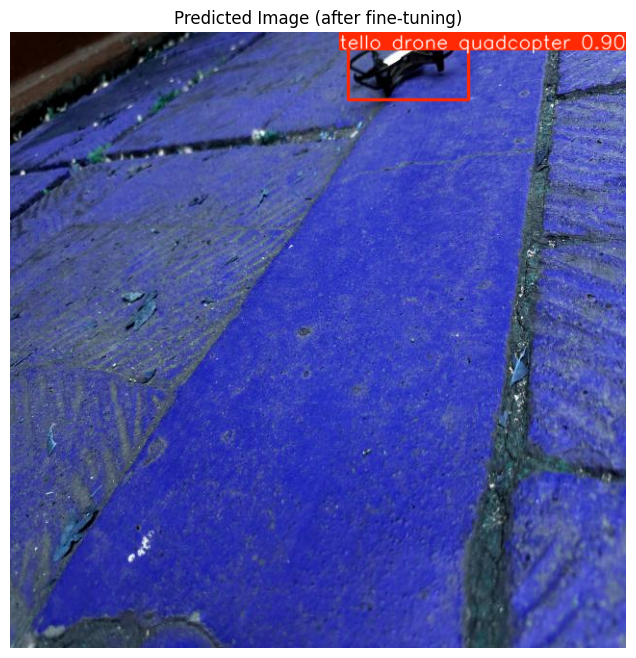

In [16]:
# Load an image and run inference / نُحمّل صورة ونُجري تنبؤًا
model = YOLO(model.trainer.best)  # Use the best weights / نستخدم أفضل أوزان محفوظة
results = model(str(test_images[0]), save=True)

# Convert result to a NumPy array and display / نحوّل النتيجة إلى صورة ونعرضها
predicted_image = results[0].plot()

plt.figure(figsize=(8, 8))
plt.imshow(predicted_image)
plt.axis("off")
plt.title("Predicted Image (after fine-tuning)")
plt.show()


## Step 7 — Failure case
When we first trained the model for only 2 epochs, it drew several extra wrong boxes around the drone with low confidence (0.27 and 0.50). After training for 6 epochs, these false detections were mostly reduced, and the model detected the drone with 0.90 confidence. This shows that the model needs enough training to avoid mistakes.

## Conclusion
Before training, the pretrained YOLOv8 model could not recognize the drone, because "drone" is not one of the COCO classes. After fine-tuning for only 6 epochs on our drone dataset, the model detected the drone correctly with high confidence (0.90 on the test image). On the validation set it reached a Precision of 0.992, a Recall of 0.966 and an mAP@50 of 0.99. This shows that a pretrained model can be adapted to detect a new object quickly using a small labeled dataset.
As a next step, we plan to deploy the model by exporting it to ONNX format,which allow it run on different platforms such as Window, Linux, Mobile devices and Web browsers.





